# Coding Assignment 2: What can a traveller learn from a year of flights?

In [1]:
import numpy as np
import pandas as pd
import plotnine as pn

flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")

## 1. Build the analysis sample

### 1(a) What one row represents, shapes, type and duplicates

In `flights`, one row is one scheduled flight record: one flight on one date, from one origin airport to one destination. In `airlines`, one row is one carrier code and its full airline name.

Flight numbers recur on different dates, so a repeated flight number is not by itself a duplicate. Only exact duplicate rows across all original columns would need removing.

In [2]:
print("flights (rows, columns):", flights.shape)
print("airlines (rows, columns):", airlines.shape)
print("arr_delay type:", flights["arr_delay"].dtype)
print("exact duplicate flight rows:", flights.duplicated().sum())

flights (rows, columns): (336776, 19)
airlines (rows, columns): (16, 2)
arr_delay type: float64


exact duplicate flight rows: 0


There are no exact duplicate rows, so no rows are removed.

### 1(b) Known and missing arrival delays, and the late-arrival indicator

In [3]:
# True for a delay of 15 minutes or more
flights["late_arrival"] = (flights["arr_delay"] >= 15).astype("boolean")
# Keep the outcome missing when the delay is missing
missing = flights["arr_delay"].isna()
flights.loc[missing, "late_arrival"] = pd.NA

print("flights with known arrival delay:", (~missing).sum())
print("flights with missing arrival delay:", missing.sum())
print("flights in total:", len(flights))
print("the two counts add up to the total:", (~missing).sum() + missing.sum() == len(flights))

flights with known arrival delay: 327346
flights with missing arrival delay: 9430
flights in total: 336776
the two counts add up to the total: True


The rule applied to an early arrival, 14 minutes, exactly 15 minutes and a missing value:

In [4]:
demo = pd.DataFrame({"arr_delay": [-5, 14, 15, np.nan]})
demo["late_arrival"] = (demo["arr_delay"] >= 15).astype("boolean")
demo.loc[demo["arr_delay"].isna(), "late_arrival"] = pd.NA
print(demo.to_string(index=False))

 arr_delay  late_arrival
      -5.0         False
      14.0         False
      15.0          True
       NaN          <NA>


## 2. Attach the airline names

In [5]:
print("lookup codes:", len(airlines), "| each code occurs once:", airlines["carrier"].is_unique)
print("flights before join:", len(flights))

sample = flights.merge(airlines, on="carrier", how="left", validate="many_to_one")
print("flights after join:", len(sample))
print("flights with unmatched carrier code:", sample["name"].isna().sum())

lookup codes: 16 | each code occurs once: True
flights before join: 336776
flights after join: 336776
flights with unmatched carrier code: 0


## 3. Give the editor a table they can check

### 3(a) Five busiest airlines and all airlines combined

In [6]:
by_airline = sample.groupby(["carrier", "name"], as_index=False).agg(
    scheduled_flights=("carrier", "size"),
    known_arrivals=("late_arrival", "count"),
    late_arrivals=("late_arrival", "sum"),
)
top5 = by_airline.sort_values("scheduled_flights", ascending=False).head(5)
top5 = top5[["name", "scheduled_flights", "known_arrivals", "late_arrivals"]]

all_row = pd.DataFrame({
    "name": ["All airlines combined"],
    "scheduled_flights": [len(sample)],
    "known_arrivals": [sample["late_arrival"].count()],
    "late_arrivals": [sample["late_arrival"].sum()],
})

report = pd.concat([top5, all_row], ignore_index=True)
report["percent_late"] = 100 * report["late_arrivals"] / report["known_arrivals"]

display_table = report.rename(columns={
    "name": "Airline",
    "scheduled_flights": "Scheduled flights",
    "known_arrivals": "Flights with known arrival delay",
    "late_arrivals": "Late arrivals (15+ min)",
    "percent_late": "Percent late (%)",
})
print(display_table.round({"Percent late (%)": 1}).to_string(index=False))

                 Airline  Scheduled flights  Flights with known arrival delay  Late arrivals (15+ min)  Percent late (%)
   United Air Lines Inc.              58665                             57782                    13004              22.5
         JetBlue Airways              54635                             54049                    14567              27.0
ExpressJet Airlines Inc.              54173                             51108                    16399              32.1
    Delta Air Lines Inc.              48110                             47658                     9038              19.0
  American Airlines Inc.              32729                             31947                     6203              19.4
   All airlines combined             336776                            327346                    80100              24.5


### 3(b) Recompute one airline from its flight records

In [7]:
ua = sample.loc[sample["carrier"] == "UA"]
numerator = (ua["arr_delay"] >= 15).sum()
denominator = ua["arr_delay"].notna().sum()
print("numerator, late arrivals:", numerator)
print("denominator, flights with known arrival delay:", denominator)
print(f"percent late: {numerator} / {denominator} = {100 * numerator / denominator:.1f}%")

ua_row = report.loc[report["name"] == "United Air Lines Inc."].iloc[0]
print("table row:", ua_row["late_arrivals"], "/", ua_row["known_arrivals"], "=", round(ua_row["percent_late"], 1), "%")
same_numerator = numerator == ua_row["late_arrivals"]
same_denominator = denominator == ua_row["known_arrivals"]
print("agrees with the table:", same_numerator and same_denominator)

numerator, late arrivals: 13004
denominator, flights with known arrival delay: 57782
percent late: 13004 / 57782 = 22.5%
table row: 13004 / 57782 = 22.5 %
agrees with the table: True


### 3(c) Alternative denominator: all scheduled flights

In [8]:
late_total = sample["late_arrival"].sum()
known_total = sample["late_arrival"].count()
all_total = len(sample)

headline = 100 * late_total / known_total
alternative = 100 * late_total / all_total
print(f"headline, known arrival delays: {late_total:,} / {known_total:,} = {headline:.2f}%")
print(f"alternative, all scheduled flights: {late_total:,} / {all_total:,} = {alternative:.2f}%")
print(f"change: {alternative - headline:+.2f} percentage points")

headline, known arrival delays: 80,100 / 327,346 = 24.47%
alternative, all scheduled flights: 80,100 / 336,776 = 23.78%
change: -0.69 percentage points


The alternative denominator counts every scheduled flight record, including flights with no arrival delay recorded. Those flights are not counted as late, so the rate falls.

## 4. Pitch and illustrate your own finding

### 4(a) The pitch

**Reader:** a traveller with a connection in New York, deciding whether a late departure will also make them late.

**Comparison:** the share of flights arriving 15 or more minutes late, for each departure-delay band.

**Measure:** flights with a known departure delay and a known arrival delay. Bands by departure delay: 0 or early, 1-14, 15-29, 30-59 and 60+ minutes late. The 15-minute cutoff is the same as in Question 1.

In [9]:
has_both_delays = sample["dep_delay"].notna() & sample["arr_delay"].notna()
pitch = sample.loc[has_both_delays].copy()
pitch["late_flag"] = pitch["late_arrival"].astype(float)

band_edges = [-np.inf, 0, 14, 29, 59, np.inf]
band_names = ["0 or early", "1-14", "15-29", "30-59", "60+"]
pitch["departure_band"] = pd.cut(pitch["dep_delay"], bins=band_edges, labels=band_names)

print("flights behind the figure:", len(pitch))

flights behind the figure: 327346


### 4(b) First version of the figure

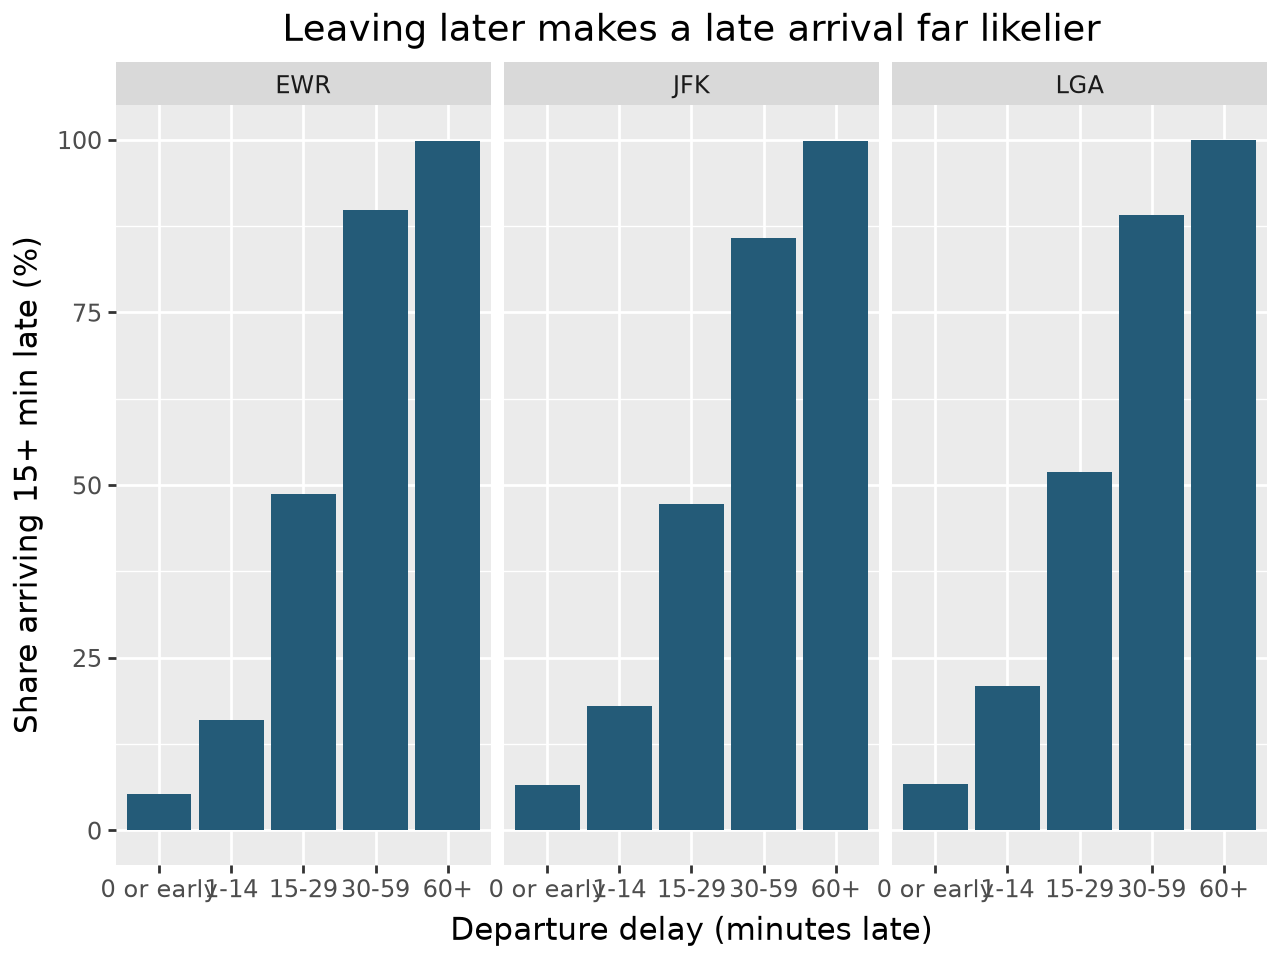

In [10]:
by_band = pitch.groupby(["departure_band", "origin"], observed=True, as_index=False).agg(
    flights=("late_flag", "size"),
    share_late=("late_flag", "mean"),
)
by_band["share_late_pct"] = 100 * by_band["share_late"]

first = (
    pn.ggplot(by_band, pn.aes("departure_band", "share_late_pct"))
    + pn.geom_col(fill="#245b78")
    + pn.facet_wrap("~origin", ncol=3)
    + pn.labs(
        title="Leaving later makes a late arrival far likelier",
        x="Departure delay (minutes late)",
        y="Share arriving 15+ min late (%)",
    )
)
first

### 4(c) Final version: one change, separate panels replaced by one panel with colour

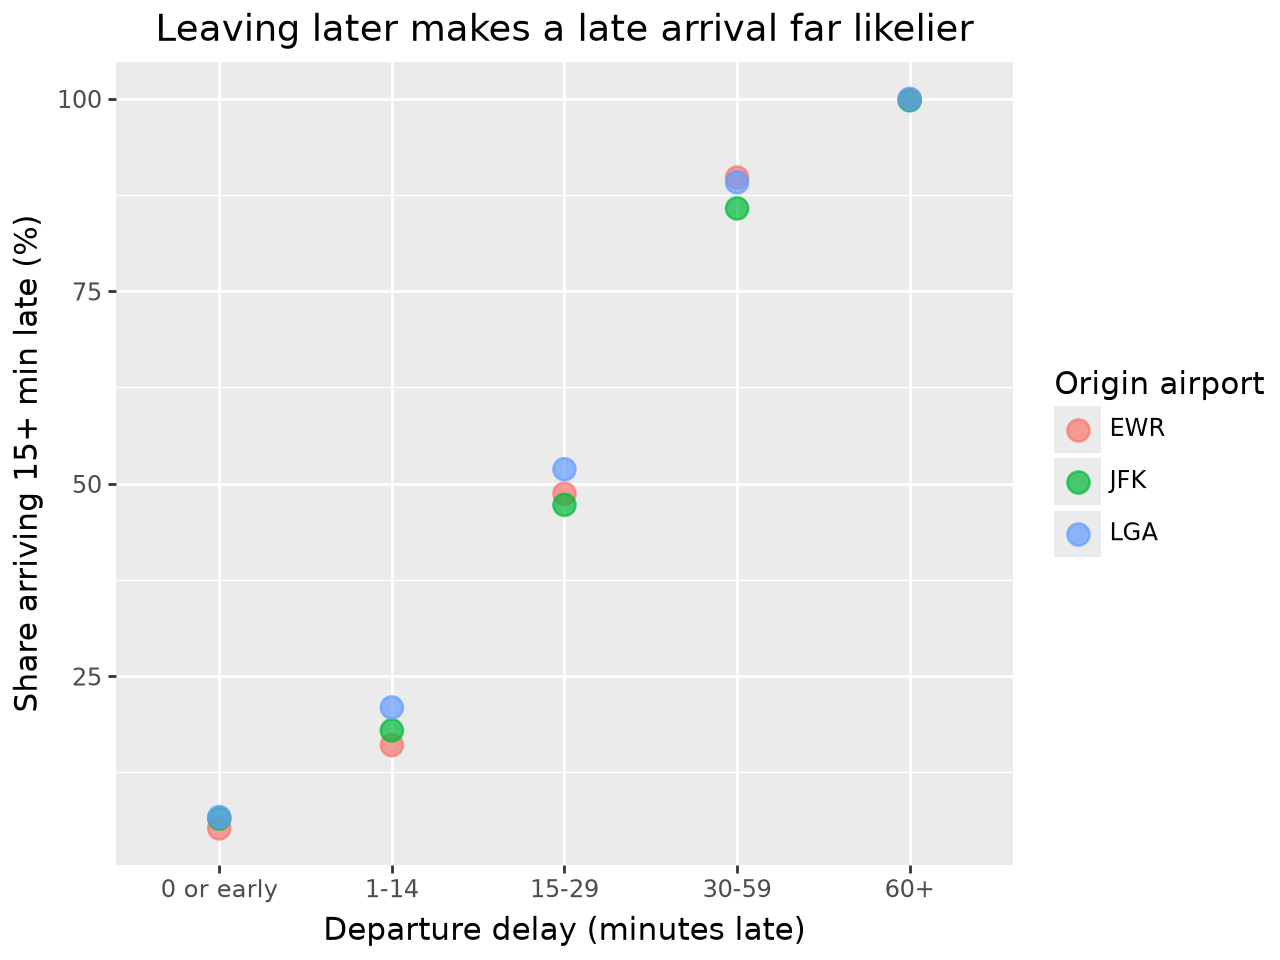

In [11]:
final = (
    pn.ggplot(by_band, pn.aes("departure_band", "share_late_pct", color="origin"))
    + pn.geom_point(size=4, alpha=0.7)
    + pn.labs(
        title="Leaving later makes a late arrival far likelier",
        x="Departure delay (minutes late)",
        y="Share arriving 15+ min late (%)",
        color="Origin airport",
    )
)
final

In [12]:
final.save("figure.png", width=9, height=5, dpi=200, verbose=False)

**The edit.** Putting the three airports in one panel with a colour for each makes it easier to compare them within each departure band. The separate panels showed each airport's bar height on its own, and the points now overlap where the airports are close, so small differences are harder to see.

### 4(d) Numbers for the caption

In [13]:
all_by_band = pitch.groupby("departure_band", observed=True, as_index=False).agg(
    flights=("late_flag", "size"),
    share_late=("late_flag", "mean"),
)
all_by_band["share_late_pct"] = (100 * all_by_band["share_late"]).round(1)
print(all_by_band.to_string(index=False))
print("total flights:", all_by_band["flights"].sum())

departure_band  flights  share_late  share_late_pct
    0 or early   199601    0.061678             6.2
          1-14    55325    0.179160            17.9
         15-29    23396    0.490810            49.1
         30-59    22222    0.883179            88.3
           60+    26802    0.998731            99.9
total flights: 327346


Of 327,346 flights from EWR, JFK and LGA in 2013 with known departure and arrival delays, 6.2% of flights that left early or on time arrived 15 or more minutes late. The share is 49.1% for departures 15-29 minutes late and 99.9% for departures 60 or more minutes late. Source: nycflights13, from U.S. Bureau of Transportation Statistics data, January-December 2013. Limit: this is an association in one year at three airports; it does not show that the departure delay caused the late arrival.